# TP 3 (Predicion Lineal)

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import resample_poly, correlate
from scipy.linalg import solve_toeplitz

# Parte 1 (Grabaciones)


El primer ejercicio consiste únicamente en preparar correctamente las señales que se utilizarán después. Se graban los sonidos /a/, /y/ y /sh/ con una frecuencia de muestreo de 16 kHz y se selecciona un fragmento de 1 s de cada grabación.

$$f_s = 16\ \text{kHz} = 16\,000\ \text{muestras/s}$$

Por tanto, un segundo de señal contiene 16 000 muestras. Trabajar con la misma duración y la misma frecuencia de muestreo permite comparar los tres sonidos en las mismas condiciones.

En el caso de /a/ se pide mantener el tono lo más estable posible. La razón es que /a/ es un sonido sonoro: las cuerdas vocales vibran de forma aproximadamente periódica. Si el tono cambia mucho durante el segundo analizado, también cambia el periodo de esa repetición y resulta más difícil identificarla en los ejercicios posteriores.

| Sonido | Tipo aproximado   | Qué esperamos                               |
|:------:|:-----------------:|:-------------------------------------------:|
| /a/    | Sonoro y periódico | Estructura de corto plazo + periodicidad de pitch |
| /y/    | Sonoro            | Estructura espectral y periodicidad         |
| /sh/   | No sonoro         | Comportamiento más parecido a ruido filtrado |

In [2]:
# FUNCIÓN PARA LEER EL AUDIO

def cargar_audio(nombre):

    fs, x = wavfile.read(nombre)

    # Si es estéreo, lo pasamos a mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)

    # Si no está a 16 kHz, lo remuestreamos
    if fs != 16000:

        x = resample_poly(x,16000,fs)
        fs = 16000

    # Nos quedamos con 1 segundo
    x = x[:16000]

    # Quitamos la media
    x = x - np.mean(x)

    # Normalizamos
    x = x / np.max(np.abs(x))

    return x

# Parte 2 (Predicción forward y MSE mínimo $J(M)$)

En este apartado se utiliza la predicción lineal forward. La idea es que, en lugar de mirar la señal completa, intentamos predecir cada muestra actual $x[n]$ a partir de las muestras inmediatamente anteriores. Si usamos un predictor de orden $M$, utilizamos las $M$ muestras anteriores para construir la predicción.

$$\hat{x}[n] = a_1 x[n-1] + a_2 x[n-2] + \cdots + a_M x[n-M]$$

Aquí $x[n]$ es la muestra real, $\hat{x}[n]$ es la muestra predicha, $M$ indica cuántas muestras pasadas utilizamos y $a_1, a_2, \dots, a_M$ son los coeficientes del predictor.

Por ejemplo, para $M = 2$ sólo usamos $x[n-1]$ y $x[n-2]$; para $M = 20$ usamos las veinte muestras anteriores.

Los coeficientes $a_1, a_2, \dots, a_M$ no se eligen a mano. Se calculan a partir de la propia señal para que el error de predicción sea lo más pequeño posible. Para ello el código estudia cuánto se parece la señal a versiones retrasadas de sí misma mediante la autocorrelación.

La autocorrelación $r_x[k]$ mide, de forma simplificada, cuánto se parece $x[n]$ a $x[n-k]$. Por ejemplo, $r_x[1]$ mide la relación con la muestra anterior, $r_x[10]$ con una muestra situada diez posiciones atrás, etc. Esta información es la que permite determinar qué peso debe tener cada muestra pasada en la predicción.

A partir de estas correlaciones se construye el sistema de ecuaciones $\mathbf{R}\,\mathbf{a} = \mathbf{p}$. El vector $\mathbf{a}$ contiene los coeficientes $[a_1, a_2, \dots, a_M]^T$. Resolver este sistema proporciona los coeficientes óptimos, es decir, los que minimizan el error cuadrático medio para ese valor de $M$.

Una vez obtenida la predicción, se calcula el error forward como la diferencia entre la muestra real y la predicha:

$$e_f[n] = x[n] - \hat{x}[n]$$

Si el predictor acierta, $\hat{x}[n]$ será muy parecida a $x[n]$ y $e_f[n]$ será pequeño. Para resumir el error de toda la señal en un único número se calcula el error cuadrático medio (MSE), que en el enunciado se denomina $J(M)$:

$$J(M) = \frac{1}{N} \sum_n e_f^2[n]$$

Por tanto, para cada valor de $M$ el procedimiento es siempre el mismo:

Se calcula la autocorrelación de la señal, se obtienen los coeficientes óptimos $a_1, \dots, a_M$, se forma la predicción $\hat{x}[n]$, se obtiene el error $e_f[n]$ y finalmente se calcula $J(M)$.

Después se repite todo el proceso para $M = 1, 2, 3, \dots$ y se representa $J$ frente a $M$.

## Qué hace el código con los audios antes de calcular $J(M)$

1. Lee el archivo WAV y obtiene la frecuencia de muestreo y las muestras $x[n]$.
2. Si el archivo tiene dos canales, se pasa a mono, ya que para este análisis sólo se necesita una señal.
3. Si la grabación no está a 16 kHz, se remuestrea a $f_s = 16$ kHz, tal como exige el enunciado.
4. Se selecciona un segundo de señal. A 16 kHz esto corresponde a 16 000 muestras.
5. Se elimina la media y se normaliza la amplitud. Esto centra la señal alrededor de cero y evita que diferencias de escala entre grabaciones afecten a la comparación.
6. Con la señal ya preparada se calcula la autocorrelación $r_x[k]$. A partir de ella se construyen $\mathbf{R}$ y $\mathbf{p}$ y se resuelve $\mathbf{R}\,\mathbf{a} = \mathbf{p}$ para obtener los coeficientes del predictor.
7. Finalmente se calcula el MSE mínimo $J(M)$. El código repite este cálculo para muchos valores de $M$, por lo que al final obtenemos una curva $J(M)$.

En general, al aumentar $M$ el predictor dispone de más información del pasado y $J(M)$ disminuye. Sin embargo, llega un momento en el que añadir más muestras anteriores apenas mejora la predicción. Esa transición es la que se observa mediante los llamados codos de la curva.

## Qué significa un "codo"

Un codo es una zona donde cambia claramente la pendiente de $J(M)$. Antes del codo, aumentar $M$ reduce bastante el error. Después del codo, el beneficio de seguir aumentando $M$ es mucho menor. El codo indica que el predictor acaba de capturar una estructura importante de la señal.

/tmp/ipykernel_1260/1173929679.py:5: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(nombre)


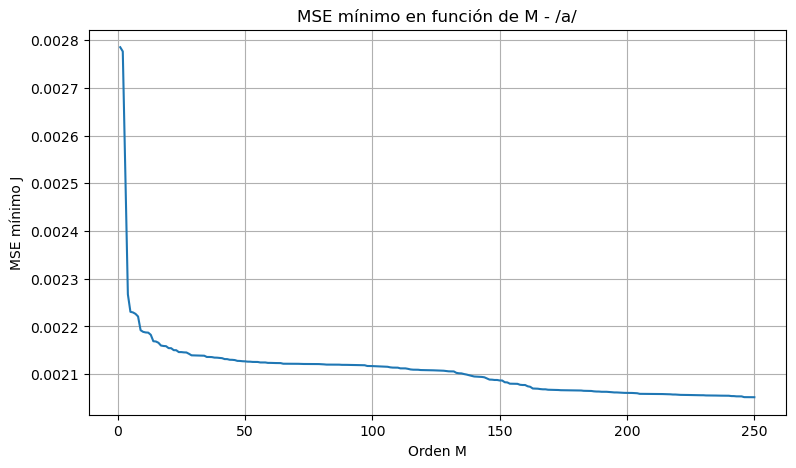

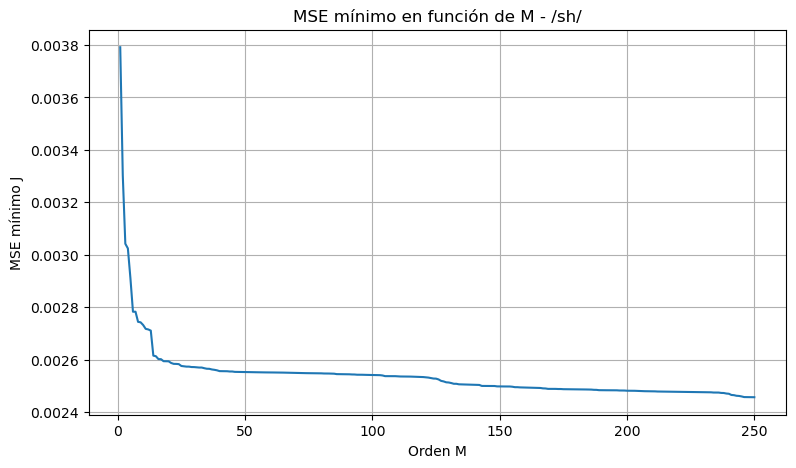

In [3]:
# FUNCIÓN PARA CALCULAR J(M)


def calcular_J(x, Mmax):

    N = len(x)

    # Autocorrelación
    r = correlate( x, x, mode="full", method="fft")

    centro = N - 1

    r = r[centro:centro + Mmax + 1] / N


    valores_J = []


    for M in range(1, Mmax + 1):

        # Matriz de autocorrelación
        # aprovechando que es Toeplitz

        p = r[1:M+1]

        a = solve_toeplitz((r[:M], r[:M]),p)

        # MSE mínimo
        J = r[0] - np.dot(p, a)

        valores_J.append(J)


    return np.array(valores_J)



# CARGAR /a/ Y /sh/


a = cargar_audio("A.wav")

sh = cargar_audio("SH.wav")



# CALCULAR J(M)


Mmax = 250

J_a = calcular_J(a,Mmax)

J_sh = calcular_J(sh,Mmax)


M = np.arange( 1, Mmax + 1)



# GRÁFICA /a/


plt.figure(figsize=(9,5))

plt.plot(M,J_a)

plt.xlabel("Orden M")
plt.ylabel("MSE mínimo J")

plt.title( "MSE mínimo en función de M - /a/")

plt.grid()

plt.show()



# GRÁFICA /sh/


plt.figure(figsize=(9,5))

plt.plot(M, J_sh)

plt.xlabel("Orden M")
plt.ylabel("MSE mínimo J")

plt.title("MSE mínimo en función de M - /sh/")

plt.grid()

plt.show()

### Interpretación de los resultados

Para /a/ se observan dos cambios de pendiente. El primero aparece para órdenes bajos, aproximadamente en la zona $M \approx 10$–$20$. Este primer codo está asociado a la correlación de corto plazo de la voz: con unos pocos coeficientes el predictor empieza a modelar la forma espectral introducida por el tracto vocal y sus resonancias.

Más adelante aparece un segundo cambio, aproximadamente alrededor de $M \approx 140$–$160$. La vocal /a/ es periódica, por lo que una muestra se parece a otra situada aproximadamente un periodo de pitch antes. Cuando $M$ alcanza ese retardo, el predictor puede aprovechar esa periodicidad y el MSE vuelve a reducirse de forma apreciable.

$$N_0 \approx \frac{f_s}{f_0}$$

Si el segundo codo se sitúa cerca de $M \approx 150$ y $f_s = 16\,000$ Hz, la frecuencia fundamental asociada sería aproximadamente $f_0 \approx 16\,000/150 \approx 107$ Hz, un valor razonable para una voz sostenida.

Para /sh/ se observa principalmente un único codo en órdenes bajos. Esto concuerda con que /sh/ es un sonido no sonoro: no existe una vibración periódica clara de las cuerdas vocales y, por tanto, no aparece un segundo codo asociado a un periodo de pitch.

# Parte 3 (Respuesta en frecuencia del filtro del error de predicción)

El tercer ejercicio utiliza los coeficientes obtenidos por el predictor, pero no pide representar el predictor directamente. Pide representar el filtro que genera el error de predicción.

## Predictor frente a filtro del error

El predictor calcula una estimación de $x[n]$:

$$\hat{x}[n] = a_1 x[n-1] + a_2 x[n-2] + \cdots + a_M x[n-M]$$

Como $e_f[n] = x[n] - \hat{x}[n]$, podemos escribir:

$$e_f[n] = x[n] - a_1 x[n-1] - a_2 x[n-2] - \cdots - a_M x[n-M]$$

Esto equivale a pasar $x[n]$ por un filtro FIR cuyos coeficientes son:

$$\bar{\mathbf{a}} = [1,\ -a_1,\ -a_2,\ \dots,\ -a_M]$$

Éste es el filtro del error de predicción. Su función es eliminar de la voz aquello que el predictor considera predecible. Por eso su salida es precisamente $e_f[n]$.

$$x[n] \;\longrightarrow\; \boxed{A(z)} \;\longrightarrow\; e_f[n]$$

## Por qué se representa $H(e^{j\omega})$

La respuesta en frecuencia indica qué frecuencias atenúa o deja pasar el filtro del error. Si la voz tiene una resonancia fuerte y muy predecible en cierta zona, el filtro tiende a crear un valle alrededor de esa frecuencia para eliminarla del residual. El objetivo ideal es que el error conserve poca estructura y se parezca más a ruido.

El ejercicio pide repetir este cálculo para $M = 1, 2, 4, 8, 16, 32$ y $64$. Así se ve cómo aumenta la capacidad del filtro para modelar la señal a medida que aumenta su orden.

/tmp/ipykernel_1260/1705536581.py:14: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(nombre)


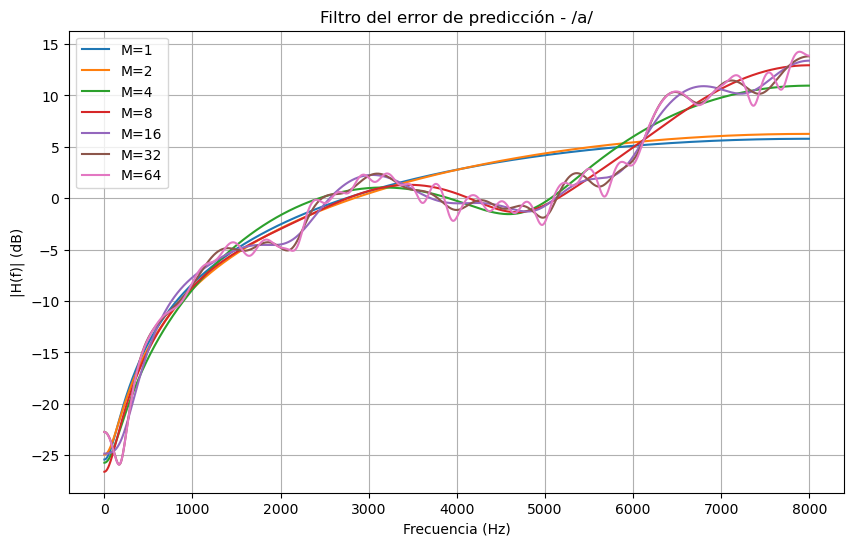

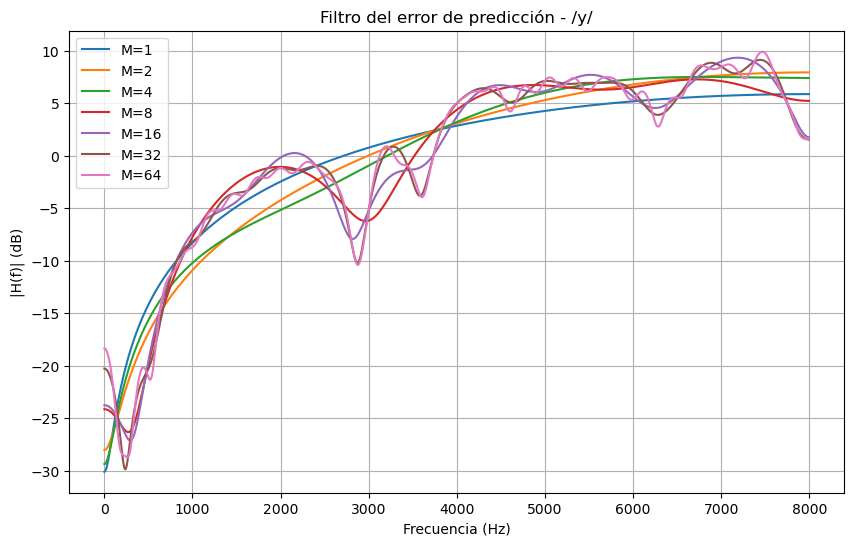

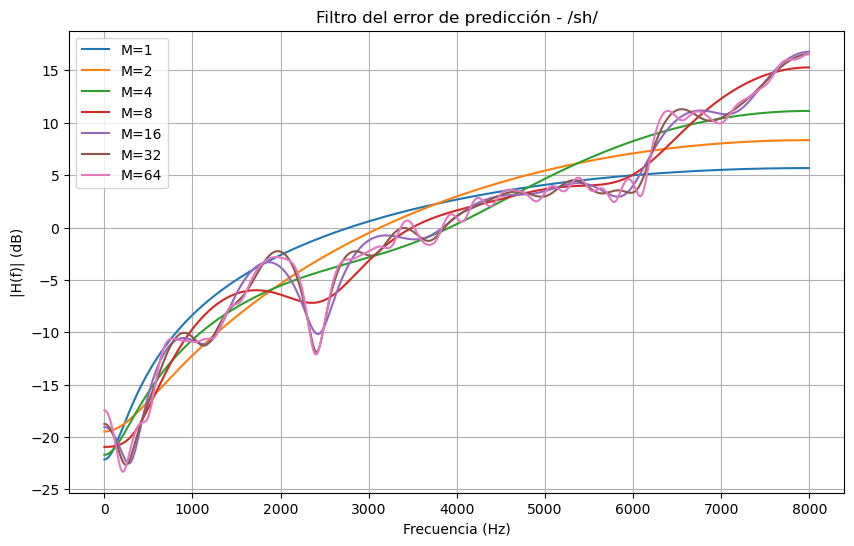

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.io import wavfile
from scipy.signal import resample_poly, freqz
from scipy.linalg import toeplitz



# LEER AUDIO

def leer_audio(nombre):

    fs, x = wavfile.read(nombre)

    # Si es estéreo, pasar a mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)

    # Pasar a 16 kHz si hace falta
    if fs != 16000:
        x = resample_poly(x, 16000, fs)
        fs = 16000

    # Usar 1 segundo
    x = x[:16000]

    # Quitar media
    x = x - np.mean(x)

    # Normalizar
    x = x / np.max(np.abs(x))

    return x, fs



# CALCULAR COEFICIENTES DEL PREDICTOR


def predictor(x, M):

    N = len(x)

    # autocorrelación
    r = np.correlate(x, x, mode="full")

    r = r[N-1:N+M] / N

    # Matriz R
    R = toeplitz(r[:M])

    # Vector p
    p = r[1:M+1]

    # coeficientes óptimos
    a = np.linalg.solve(R, p)

    return a



# VALORES DE M

valores_M = [1, 2, 4, 8, 16, 32, 64]



# AUDIO /a/

x, fs = leer_audio("A.wav")

plt.figure(figsize=(10,6))

for M in valores_M:

    a = predictor(x, M)

    # FILTRO DEL ERROR
    filtro_error = np.concatenate(([1], -a))

    f, H = freqz(filtro_error,worN=2048,fs=fs)

    plt.plot( f,20*np.log10(np.abs(H) + 1e-12),label=f"M={M}")


plt.xlabel("Frecuencia (Hz)")
plt.ylabel("|H(f)| (dB)")
plt.title("Filtro del error de predicción - /a/")
plt.legend()
plt.grid()
plt.show()

#AUDIO Y

x, fs = leer_audio("Y.wav")

plt.figure(figsize=(10,6))

for M in valores_M:

    a = predictor(x, M)

    filtro_error = np.concatenate(([1], -a))

    f, H = freqz(filtro_error,worN=2048,fs=fs)

    plt.plot(f,20*np.log10(np.abs(H) + 1e-12),label=f"M={M}")

plt.xlabel("Frecuencia (Hz)")
plt.ylabel("|H(f)| (dB)")
plt.title("Filtro del error de predicción - /y/")
plt.legend()
plt.grid()
plt.show()

#AUDIO SH

x, fs = leer_audio("SH.wav")

plt.figure(figsize=(10,6))

for M in valores_M:

    a = predictor(x, M)

    filtro_error = np.concatenate(([1], -a))

    f, H = freqz(filtro_error, worN=2048,fs=fs)

    plt.plot(f, 20*np.log10(np.abs(H) + 1e-12), label=f"M={M}")


plt.xlabel("Frecuencia (Hz)")
plt.ylabel("|H(f)| (dB)")
plt.title("Filtro del error de predicción - /sh/")
plt.legend()
plt.grid()
plt.show()

## Interpretación de las curvas

Para órdenes muy bajos, como $M = 1$ o $M = 2$, el filtro sólo puede describir una tendencia espectral muy simple. Las curvas son suaves porque hay pocos coeficientes disponibles.

Al pasar a $M = 4, 8, 16, 32$ y $64$ aparecen valles y variaciones más definidos. Esto significa que el filtro está aprendiendo más detalles de la estructura espectral de cada fonema y eliminando de la salida aquellas componentes que son más predecibles.

En /a/ y /y/, que son sonidos sonoros, la respuesta se vuelve progresivamente más detallada porque existe una estructura espectral y temporal importante. En /sh/ también se modela su coloración espectral, pero no aparece una periodicidad de pitch tan marcada, ya que es un sonido no sonoro.

La relación con $J(M)$ es directa: mientras aumentar $M$ produce una caída apreciable de $J$, el nuevo orden está explicando estructura adicional. Cuando $J(M)$ empieza a aplanarse, aumentar el orden modifica detalles cada vez más finos de $H(e^{j\omega})$ pero aporta una mejora pequeña en el error total.